# Evolution Simulation Canada
Canada serves as an extreme region with cold environment.

In [12]:
import utils.param_loader as param_loader
import numpy as np

from utils.evolution import run_evolution_simulation
from utils.evolution_plotting import (
    plot_grouped_trait_dynamics,
    plot_delta13C_trajectory_clean,
    plot_3d_evolution_trajectory,
    plot_pareto_front,
    plot_evolution_contour_heatmap,
)

## Environmental Parameters
Start time was shifted to 10:00 AM to be in the linear relationship window.

In [13]:
# # Canada (Winnipeg region, representative of continental temperate climate)
# param_loader.store_api_parameters(
#     set_name="canada",
#     longitude=-97.1384,
#     latitude=49.8951,
#     date="20230615",
#     time_start=10,
# )

In [14]:
params = param_loader.load_parameters(environmental_params='canada')

## Evolvable Traits

In [15]:
evolving_traits = [
    "g_bs",
    "g_m",
    "v_pmax",
    "v_cmax_mes",
    "v_cmax_bs",
    "k_c",
    "k_o",
    "k_p",
]

bounds = [
    [1e-7, 0.1],  # g_bs
    [1, 6],  # g_m
    [0.0, 200],  # v_pmax
    [0.0, 120],  # v_cmax_mes
    [0.0, 120],  # v_cmax_bs
    [10000.0, 100000.0],  # k_c
    [7500000.0, 27500000.0],  # k_o
    [1000.0, 70000.0],  # k_p
]

## Evolution Simulation

In [16]:
number_of_generations = 250
population_size = 15

In [ ]:
loaded_history = run_evolution_simulation(
    evolving_traits=evolving_traits,
    bounds=bounds,
    base_params=params,
    n_generations= number_of_generations,
    pop_size= number_of_generations,
    sigma0=0.33,  # Adjust as needed; higher = more exploration
)

Evolving:  14%|█▍        | 36/250 [05:00<25:51,  7.25s/it]

NOTE (module=cma, iteration=36):  
condition in coordinate system exceeded 1.2e+08, rescaled to 1.0e+00, 
condition changed from 1.1e+08 to 9.6e+00


Evolving:  23%|██▎       | 58/250 [07:38<23:02,  7.20s/it]

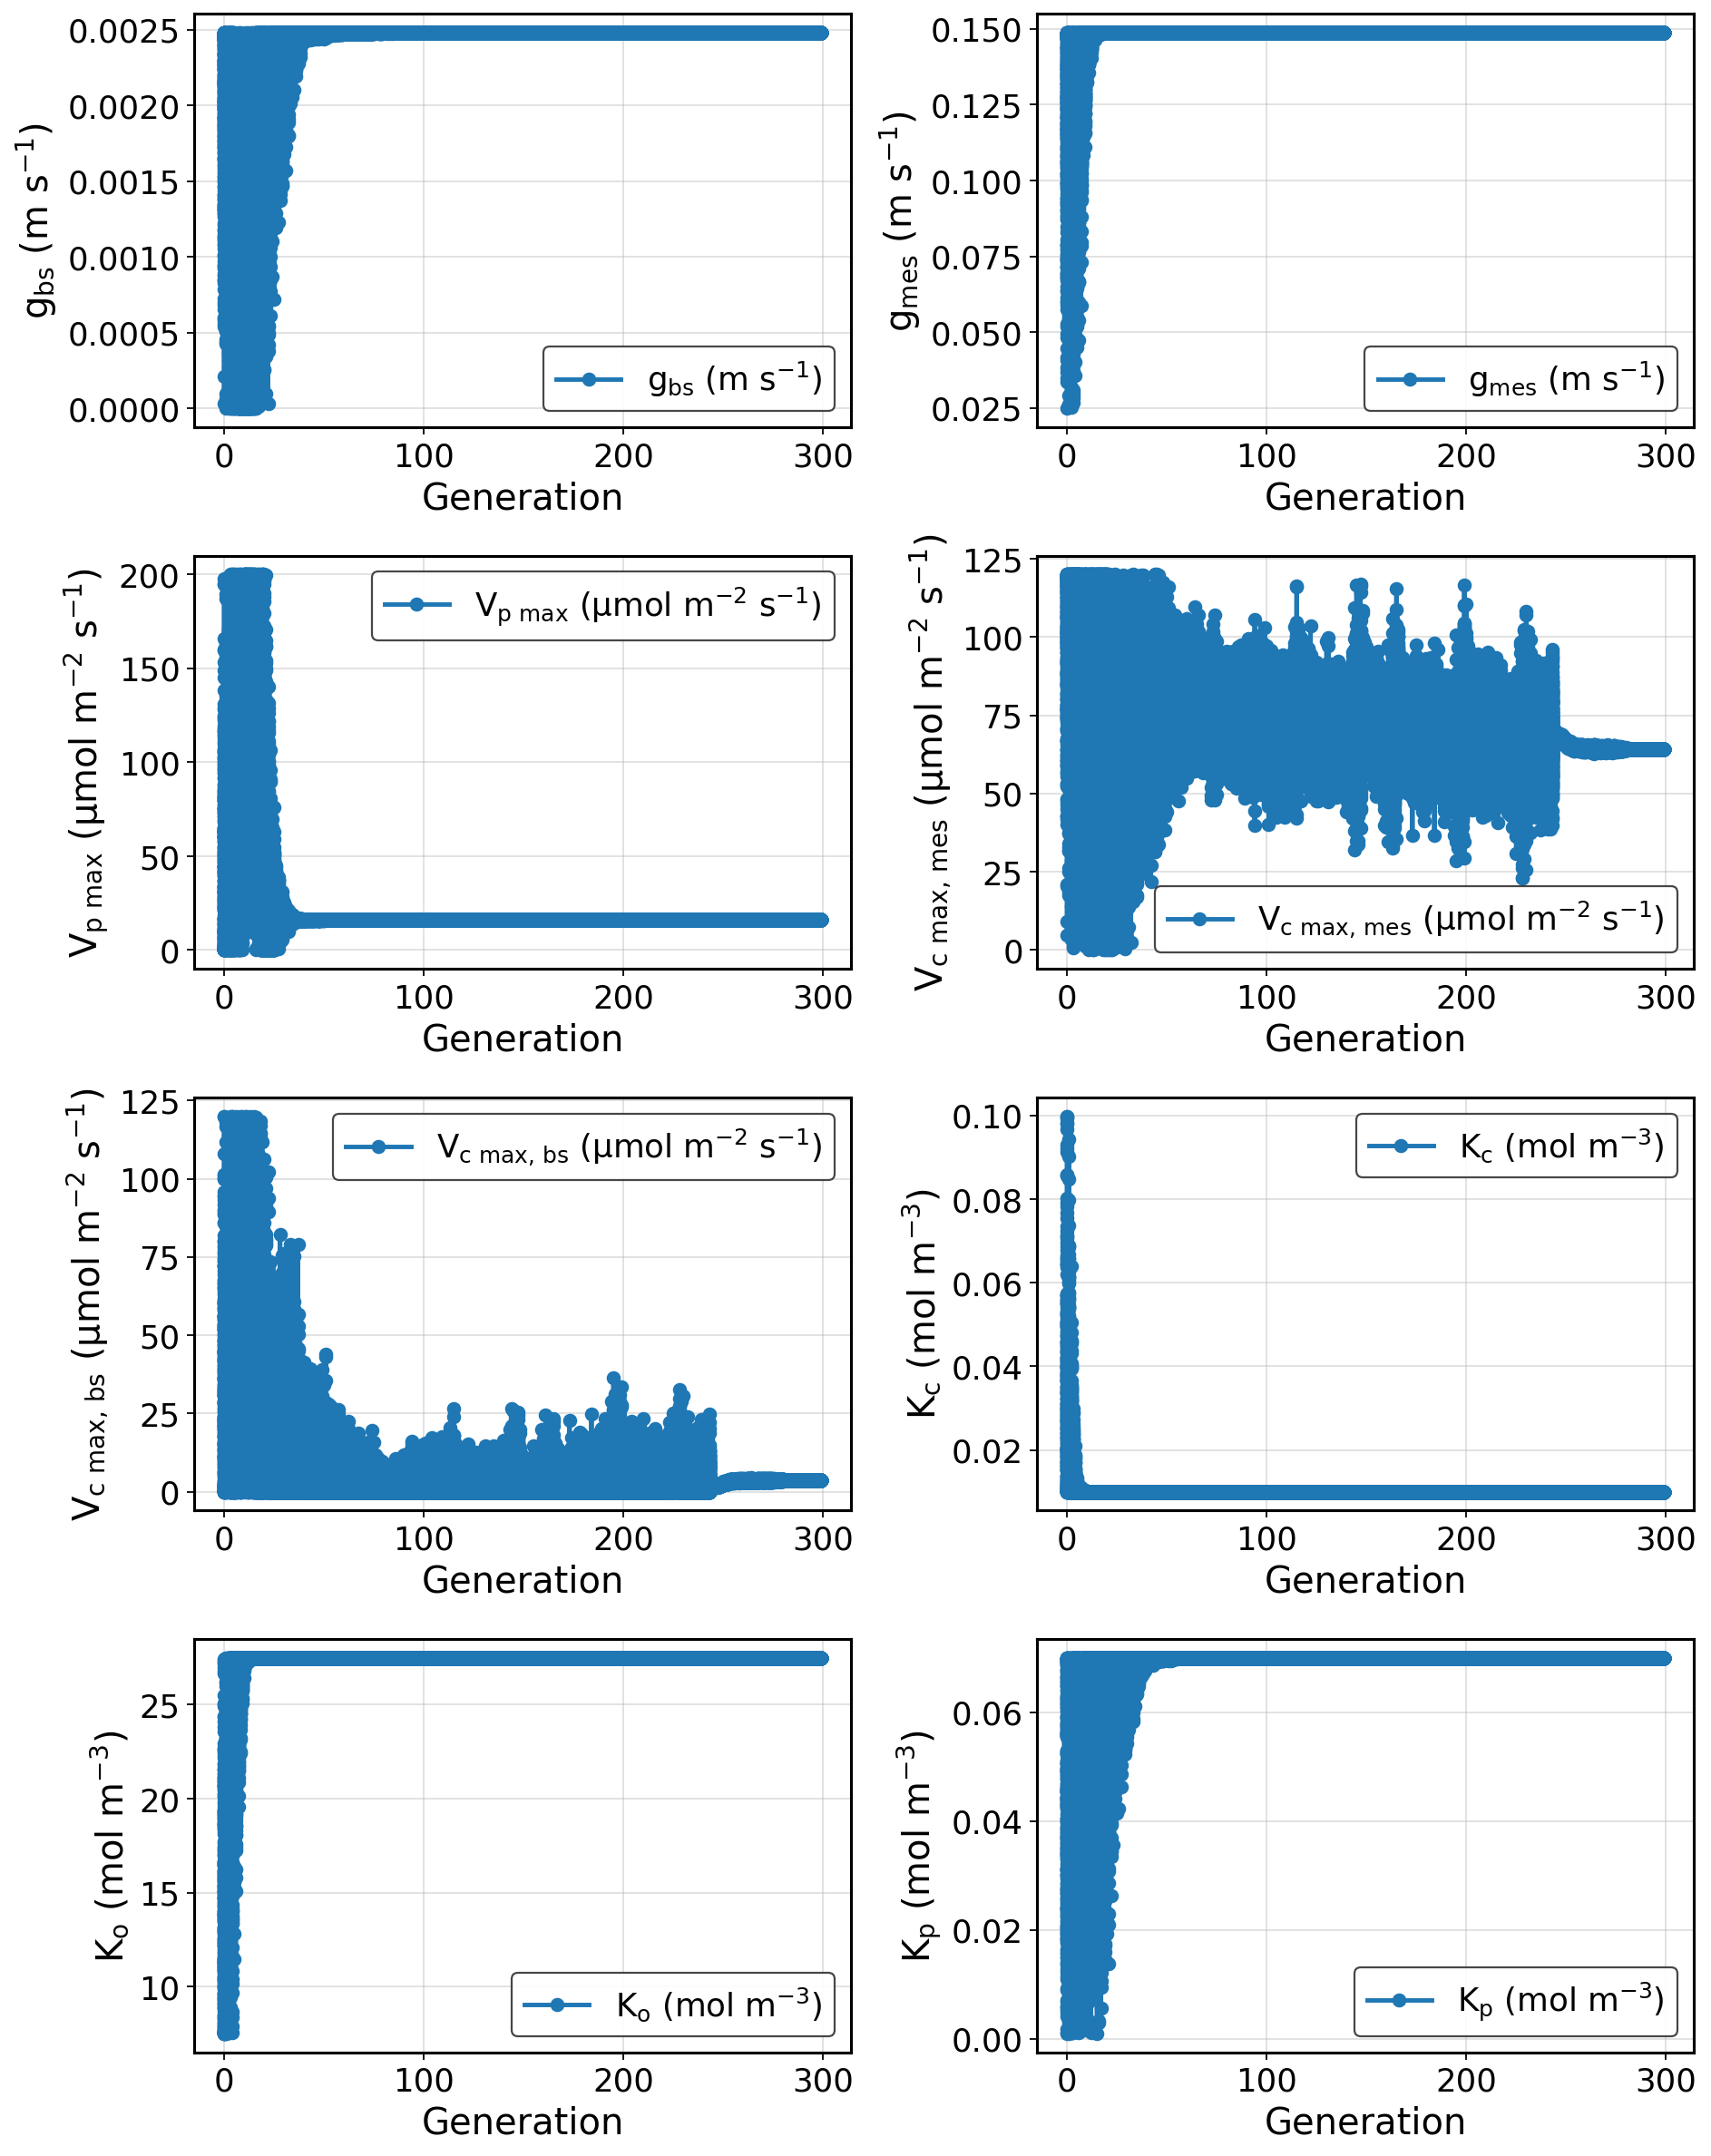

In [ ]:
trait_names = [
    "$g_{\\text{bs}}$ (m s$^{-1}$)",
    "$g_{\\text{mes}}$ (m s$^{-1}$)",
    "$V_{p~\\max}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, mes}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, bs}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$K_c$ (mol m$^{-3}$)",
    "$K_o$ (mol m$^{-3}$)",
    "$K_p$ (mol m$^{-3}$)"
]

# Plot trait dynamics
plot_grouped_trait_dynamics(loaded_history["traits"], 
                            evolving_traits, 
                            trait_names, 
                            loaded_history["delta13C_generations"],
                            save_path="plots/evolution/canada/single_traits_canada.png")

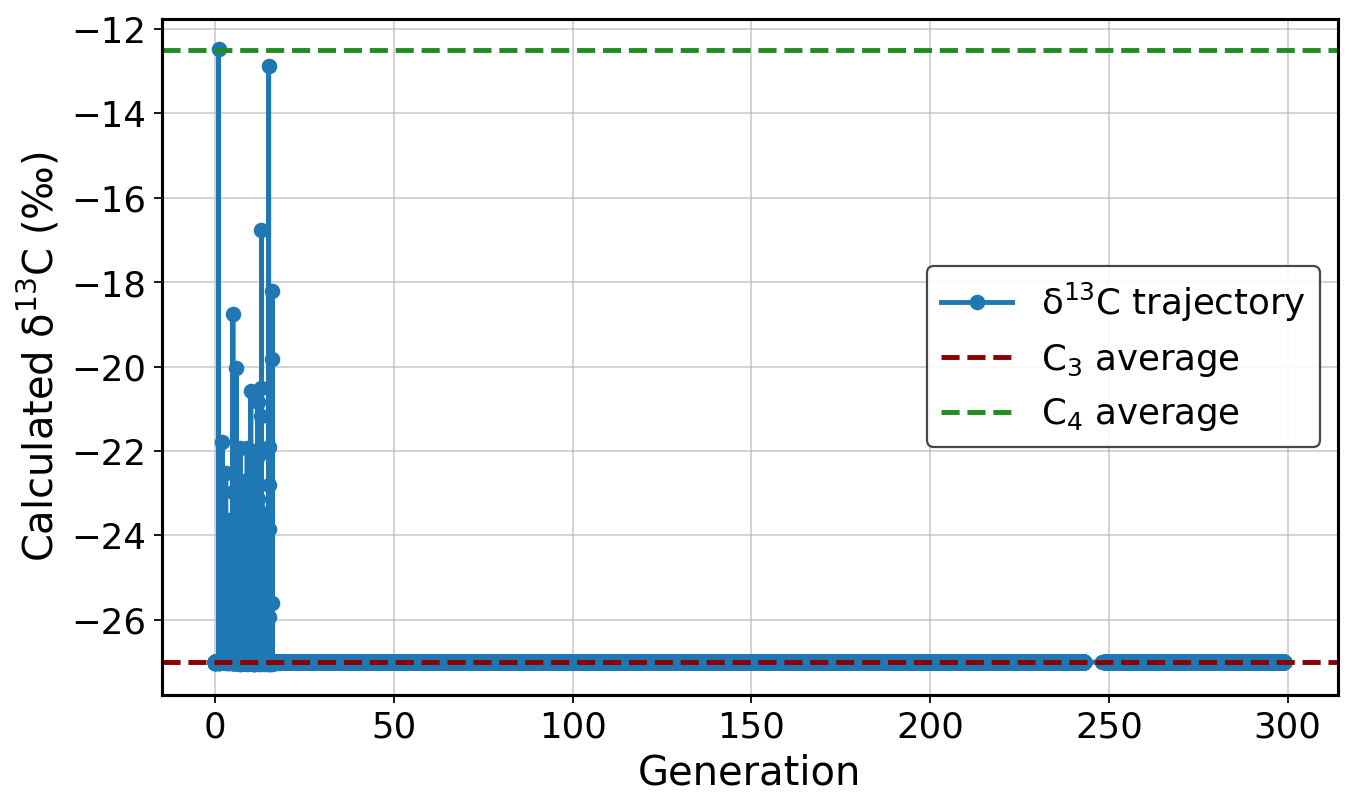

In [ ]:
# Plot δ13C trajectory if valid data exists
if any(np.isfinite(d) for d in loaded_history["delta13C"]):
    plot_delta13C_trajectory_clean(
        loaded_history["delta13C"], 
        loaded_history["delta13C_generations"],
        save_path="plots/evolution/canada/delta13C_trajectory_canada.png"
    )
else:
    print("[INFO] No valid δ13C data to plot.")

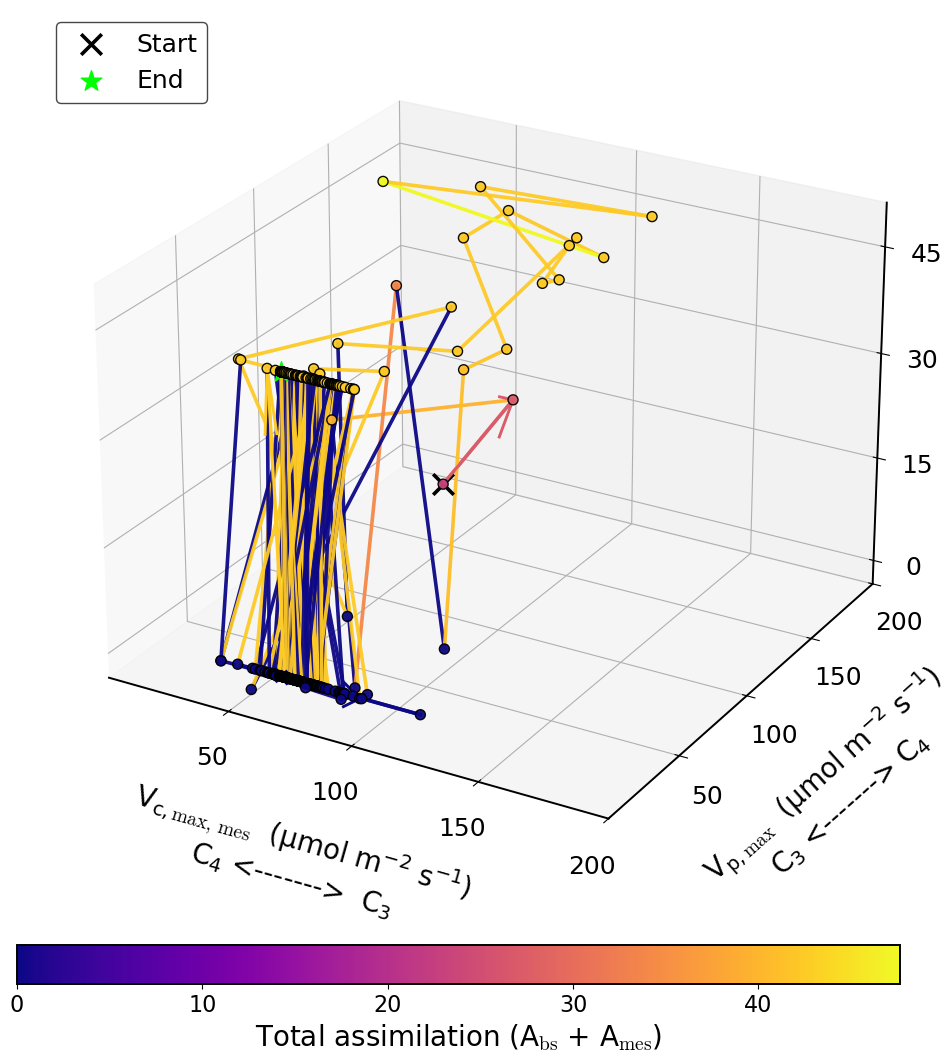

In [ ]:
# Select elite individuals (e.g., top per generation or last generation)
elite_indices = list(
    range(
        0,
        len(loaded_history["traits"]),
        len(loaded_history["traits"]) // number_of_generations,
    )
)
elite_traits = [loaded_history["traits"][i] for i in elite_indices]
elite_fitness = [loaded_history["fitness"][i] for i in elite_indices]

# 3D evolution trajectory
plot_3d_evolution_trajectory(elite_traits, elite_fitness, "v_cmax_mes", "v_pmax",
                             save_path="plots/evolution/canada/3d_evolution_trajectory_canada.png")

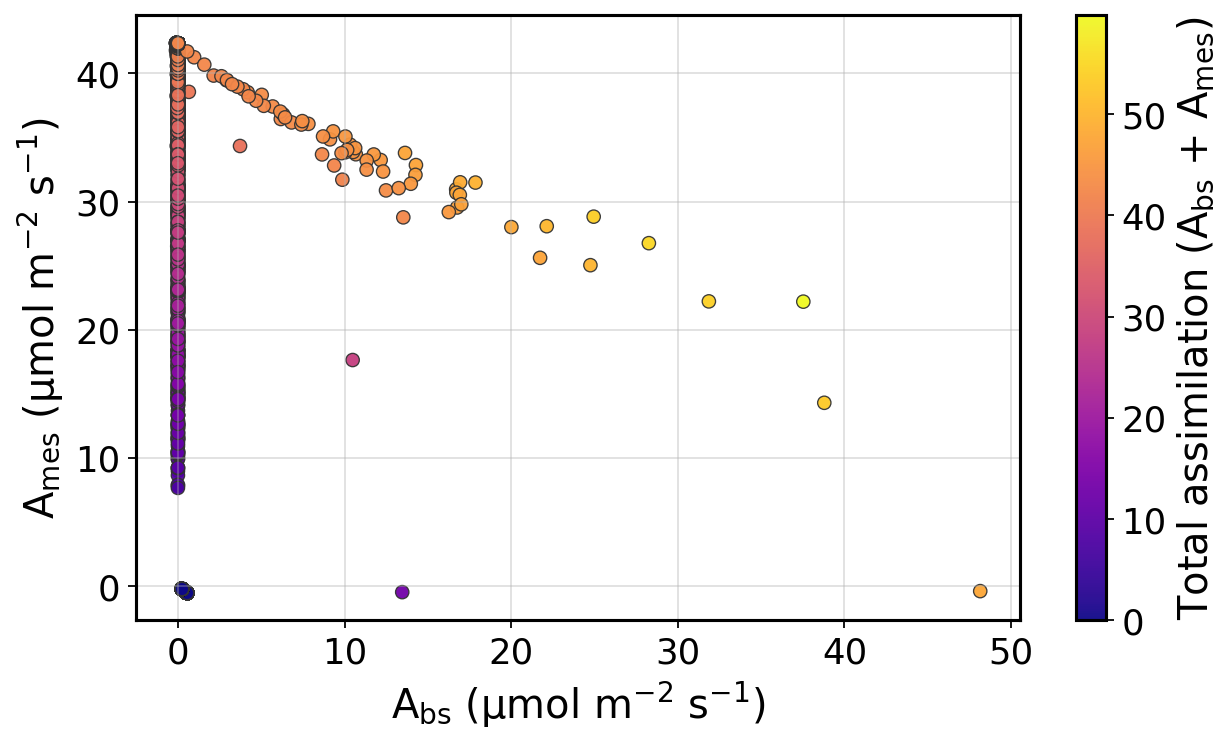

In [ ]:
def safe_extract(lst, idx):
    """Safely get element at index, else np.nan."""
    return lst[idx] if idx < len(lst) else np.nan

# Pareto front plot
plot_pareto_front(
    fitness_bs=[
        safe_extract(loaded_history["fitness_bs"], i)
        for i in range(0, len(loaded_history["fitness_bs"]))
    ],
    fitness_mes=[
        safe_extract(loaded_history["fitness_mes"], i)
        for i in range(0, len(loaded_history["fitness_mes"]))
    ],
    save_path="plots/evolution/canada/pareto_front_canada.png"
)

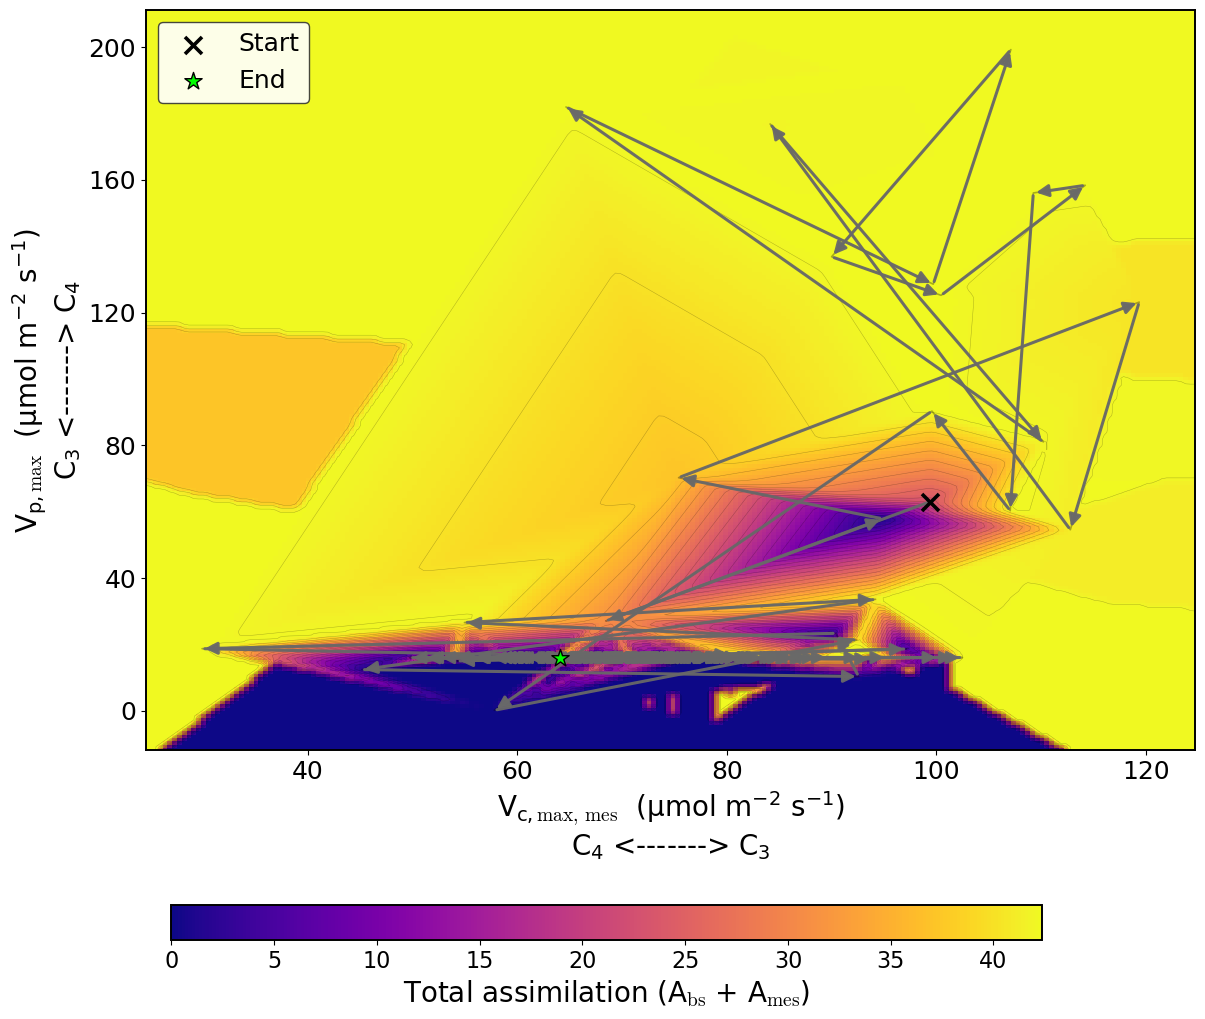

In [ ]:
# Select elite individuals (same logic)
elite_indices = list(
    range(
        0, len(loaded_history["traits"]), max(1, len(loaded_history["traits"]) // 250)
    )
)
elite_traits = [loaded_history["traits"][i] for i in elite_indices]
elite_fitness = [loaded_history["fitness"][i] for i in elite_indices]

# 2D contour heat map with evolution arrows
plot_evolution_contour_heatmap(
    elite_traits,
    elite_fitness,
    trait_x="v_cmax_mes",
    trait_y="v_pmax",
    save_path="plots/evolution/canada/contour_heatmap_canada.png",  # adjust path as needed
    cmap_name="plasma",  # projector-friendly
    n_levels=24,  # smooth contours
    # arrow_density=12,  # fewer arrows → increase this number
)